# CS06 - Solar integration: reverse power flow, voltage rise, hosting capacity and storage

**Problem type:** integration of variable renewables in a weak part of the grid.
**Source:** Travaux pratiques, case 5, on the IEEE 14-bus system, with a **real** solar
profile (Niamey, 16 March 2023, the clearest day of the first quarter).

## 1. Context
A solar plant is connected at **bus 14**, the weakest node of the IEEE 14-bus system
(local load 14.9 MW at the evening peak). Scenarios of the exercise:

| Scenario | Configuration |
|---|---|
| S0 | no solar |
| S1 | 50 MW of solar |
| S2 | 100 MW of solar |
| S3 | 100 MW of solar + battery 50 MW / 200 MWh |
| S4 | S3 + inverters absorbing reactive power (power factor 0.95) |

## 2. Exercise
1. What is the **hosting capacity** of bus 14 (largest PV plant without violating
   1.06 p.u. or a thermal rating)? Which constraint binds?
2. From which PV size does the power flow **reverse** on the lines feeding bus 14?
3. Run the five scenarios over 24 hours. Compare voltages, reverse-flow hours, loadings
   and losses.
4. Does the battery solve the problem? What else is needed?

## 3. Theory
* **Reverse power flow:** when local generation exceeds local demand, the surplus flows
  back towards the rest of the grid: $P_{surplus} = P_{PV} - P_{load}$ (minus losses).
* **Voltage rise:** $\Delta V \approx (RP + XQ)/V$ with $P$ now flowing **out** of the bus:
  the voltage at the PV bus **rises**. Absorbing reactive power ($Q < 0$) compensates it.
* **Hosting capacity:** the largest generation a node can accept before the first limit
  (voltage, current, protection) is violated.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pscs").exists())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import pypsa
import matplotlib.pyplot as plt

import pscs
from pscs.kpi import run_pf, kpis, branch_table, enforce_q_limits, one_snapshot
from pscs.plotting import SERIES, ENTITY, CRITICAL, GOOD, INK2, MUTED, save, limit_line

DATA, FIG, TAB = pscs.setup()
day = pypsa.Network(DATA / "networks" / "ieee14_pv_day")
CF = day.generators_t.p_max_pu["pv14"]
QLIM = day.generators[["q_min", "q_max"]].dropna()
V_MAX = 1.06
TAN95 = np.tan(np.arccos(0.95))                     # Q/P at power factor 0.95
NOON = CF.idxmax()
print(f"PV capacity factor at noon: {CF.max():.2f}; daily yield {CF.sum():.2f} kWh/kWp")
pd.DataFrame({"PV capacity factor": CF.values,
              "load at bus 14 (MW)": day.loads_t.p_set["load_14"].values}, index=CF.index.hour).T.round(2)

PV capacity factor at noon: 0.79; daily yield 5.92 kWh/kWp


snapshot,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
PV capacity factor,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.07,0.27,0.47,...,0.74,0.62,0.46,0.25,0.05,0.00,0.0,0.00,0.00,0.00
load at bus 14 (MW),10.28,9.7,9.27,8.98,8.85,9.15,9.75,10.65,11.54,12.28,...,13.78,13.63,13.49,13.64,14.25,14.88,14.9,14.47,13.14,11.66


## 4. Hosting capacity at the hour of maximum sun (question 1)
**Which voltages are checked?** Generator and synchronous-condenser buses (1, 2, 3, 6, 8) are
held at their set points, and bus 7 is the fictitious star point of a three-winding
transformer (no customer). Limits (0.94-1.06 p.u.) apply to the **customer buses** and to the
PV bus: 4, 5, 9, 10, 11, 12, 13, 14.

Three connection strategies are compared:
1. unity power factor, original IEEE voltage set points (1.01 to 1.09 p.u.);
2. unity power factor, generator set points lowered by 0.03 p.u. (a free operational lever);
3. strategy 2 plus inverters absorbing reactive power at power factor 0.95.

In [2]:
MONITORED = ["4", "5", "9", "10", "11", "12", "13", "14"]
V_MIN, DV = 0.94, 0.03
STRATEGIES = {"unity PF, original set points": (False, 0.0),
              "unity PF, set points -0.03": (False, DV),
              "PF 0.95 absorbing, set points -0.03": (True, DV)}


def lower_set_points(m, delta):
    gen_buses = m.generators.bus[m.generators.control.isin(["PV", "Slack"])]
    m.buses.loc[gen_buses, "v_mag_pu_set"] -= delta


def at_noon(pv_mw, pf_absorb=False, delta=0.0):
    m = one_snapshot(day, NOON)
    lower_set_points(m, delta)
    m.generators_t.p_set.loc[:, "pv14"] = pv_mw
    m.generators_t.q_set.loc[:, "pv14"] = -TAN95 * pv_mw if pf_absorb else 0.0
    m.storage_units_t.p_set.loc[:, "battery14"] = 0.0
    enforce_q_limits(m, QLIM)
    return m


def check(m):
    v = m.buses_t.v_mag_pu.iloc[0][MONITORED]
    load = branch_table(m)["loading (%)"].max()
    why = ("overvoltage" if v.max() > V_MAX + 1e-9 else "undervoltage" if v.min() < V_MIN - 1e-9
           else "thermal" if load > 100 else None)
    return v.max(), v.idxmax(), v.min(), load, why


def hosting_capacity(pf_absorb, delta):
    """Largest PV size (1 MW steps) respecting 0.94-1.06 p.u. and every thermal rating."""
    ok = 0
    for p in range(0, 251):
        try:
            why = check(at_noon(p, pf_absorb, delta))[-1]
        except RuntimeError:
            why = "no load-flow solution (voltage collapse)"
        if why:
            return ok, why
        ok = p
    return ok, "none up to 250 MW"

rows = []
for name, (pf_absorb, delta) in STRATEGIES.items():
    for p in np.arange(0, 201, 10):
        try:
            m = at_noon(p, pf_absorb, delta)
        except RuntimeError:                      # beyond the nose point: no solution
            break
        vmax, bmax, vmin, load, why = check(m)
        bt = branch_table(m)
        rows.append({"strategy": name, "PV (MW)": p, "highest V (p.u.)": vmax, "at bus": bmax,
                     "lowest V (p.u.)": vmin, "max loading (%)": load,
                     "P 9->14 (MW)": bt.loc["L9-14", "P_from (MW)"],
                     "P 13->14 (MW)": bt.loc["L13-14", "P_from (MW)"]})
sweep = pd.DataFrame(rows)
sweep.to_csv(TAB / "cs06_hosting_sweep.csv", index=False)
HC = {name: hosting_capacity(*args) for name, args in STRATEGIES.items()}
hc_table = pd.DataFrame(HC, index=["hosting capacity (MW)", "first limit reached"]).T
hc_table.to_csv(TAB / "cs06_hosting_capacity.csv")
hc_table

,hosting capacity (MW),first limit reached
"unity PF, original set points",3,overvoltage
"unity PF, set points -0.03",66,overvoltage
"PF 0.95 absorbing, set points -0.03",129,undervoltage


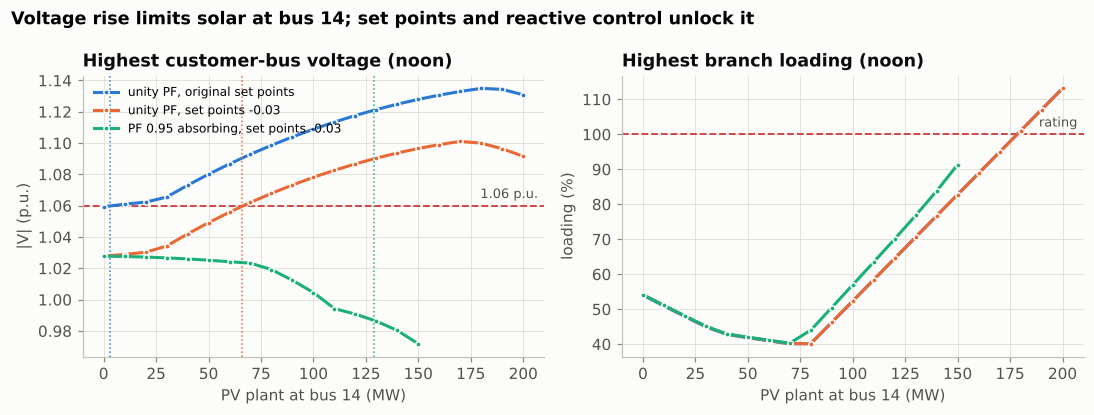

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.8))
for (name, c) in zip(STRATEGIES, SERIES):
    h = sweep[sweep.strategy == name]
    axes[0].plot(h["PV (MW)"], h["highest V (p.u.)"], "o-", ms=3.5, color=c, label=name, markeredgecolor="white")
    axes[1].plot(h["PV (MW)"], h["max loading (%)"], "o-", ms=3.5, color=c, label=name, markeredgecolor="white")
    axes[0].axvline(HC[name][0], color=c, ls=":", lw=1)
limit_line(axes[0], V_MAX, "1.06 p.u.", color=CRITICAL)
limit_line(axes[1], 100, "rating", color=CRITICAL)
axes[0].set_title("Highest customer-bus voltage (noon)"); axes[0].set_ylabel("|V| (p.u.)")
axes[1].set_title("Highest branch loading (noon)"); axes[1].set_ylabel("loading (%)")
for ax in axes:
    ax.set_xlabel("PV plant at bus 14 (MW)")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Voltage rise limits solar at bus 14; set points and reactive control unlock it",
             x=0.01, ha="left", fontweight="bold", fontsize=11.5)
fig.tight_layout()
save(fig, FIG / "cs06_hosting_capacity.png")
fig

## 5. Reverse power flow (question 2)

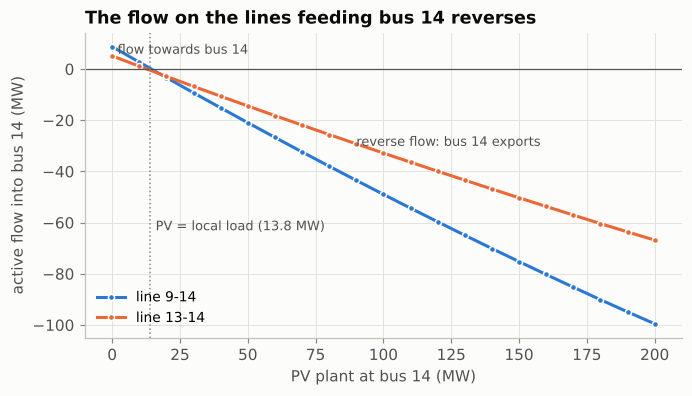

In [4]:
h = sweep[sweep.strategy == "unity PF, original set points"]
load14_noon = day.loads_t.p_set.loc[NOON, "load_14"]
fig, ax = plt.subplots(figsize=(7.0, 3.6))
ax.plot(h["PV (MW)"], h["P 9->14 (MW)"], "o-", ms=4, color=SERIES[0], label="line 9-14", markeredgecolor="white")
ax.plot(h["PV (MW)"], h["P 13->14 (MW)"], "o-", ms=4, color=SERIES[1], label="line 13-14", markeredgecolor="white")
ax.axhline(0, color=INK2, lw=0.8)
ax.axvline(load14_noon, color=MUTED, ls=":", lw=1)
ax.annotate(f"PV = local load ({load14_noon:.1f} MW)", (load14_noon, ax.get_ylim()[0] * 0.6),
            xytext=(4, 0), textcoords="offset points", fontsize=8.5, color=INK2)
ax.annotate("flow towards bus 14", (2, 6), fontsize=8.5, color=INK2)
ax.annotate("reverse flow: bus 14 exports", (90, -30), fontsize=8.5, color=INK2)
ax.set_xlabel("PV plant at bus 14 (MW)"); ax.set_ylabel("active flow into bus 14 (MW)")
ax.set_title("The flow on the lines feeding bus 14 reverses")
ax.legend(loc="lower left")
save(fig, FIG / "cs06_reverse_flow.png")
fig

Before the plant, both lines **feed** bus 14. As soon as the PV output exceeds the local
load (about 14 MW at noon), the sum of the two flows becomes negative: bus 14 **exports**.
This is the reverse power flow of the exercise ($P_{surplus} = P_{PV} - P_{load}$).
Protection settings, voltage regulators and tap changers designed for one direction of flow
must be checked.

## 6. The five scenarios over 24 hours (questions 3 and 4)
Battery rule (simple and explainable): **peak shaving**. The battery stores the PV output
above a threshold, within 50 MW, and the threshold is the lowest one whose surplus still fits
in 200 MWh: the battery cuts the **top** of the solar curve, where the voltage is highest.
The stored energy is returned evenly during the evening peak (18:00-22:00).

In [5]:
def shaving_threshold(pv, p_max=50.0, e_max=200.0, eta=0.95):
    """Lowest threshold T whose surplus above T (capped at p_max) fits in the battery."""
    lo, hi = 0.0, float(pv.max())
    for _ in range(50):
        t = (lo + hi) / 2
        lo, hi = (t, hi) if (pv - t).clip(0, p_max).sum() * eta > e_max else (lo, t)
    return hi


def battery_schedule(pv, threshold, p_max=50.0, e_max=200.0, eta=0.95):
    charge = (pv - threshold).clip(lower=0, upper=p_max)
    soc, ch = 0.0, []
    for c in charge:                                     # respect the energy capacity
        c = min(c, (e_max - soc) / eta)
        soc += c * eta
        ch.append(c)
    charge = pd.Series(ch, index=pv.index)
    evening = (pv.index.hour >= 18) & (pv.index.hour < 22)
    discharge = pd.Series(0.0, index=pv.index)
    discharge[evening] = min(p_max, soc * eta / evening.sum())
    return discharge - charge                            # PyPSA sign: + dispatch, - charging


def run_day(pv_mw, battery=False, pf_absorb=False, delta=0.0):
    m = day.copy()
    lower_set_points(m, delta)
    pv = pv_mw * CF
    m.generators_t.p_set["pv14"] = pv
    m.generators_t.q_set["pv14"] = -TAN95 * pv if pf_absorb else 0.0 * pv
    m.storage_units_t.p_set["battery14"] = (battery_schedule(pv, shaving_threshold(pv)) if battery
                                            else 0.0 * pv)
    run_pf(m)
    return m

cases = {"S0 no PV": (0, False, False), "S1 PV 50 MW": (50, False, False),
         "S2 PV 100 MW": (100, False, False), "S3 PV 100 + battery": (100, True, False),
         "S4 S3 + PF 0.95 + set points": (100, True, True, DV)}
runs = {k: run_day(*v) for k, v in cases.items()}
summary = {}
for k, m in runs.items():
    v14 = m.buses_t.v_mag_pu["14"]
    inflow = m.lines_t.p0["L9-14"] + m.lines_t.p0["L13-14"]
    br = pd.concat([m.lines_t.p0.abs().combine(m.lines_t.p1.abs(), np.maximum).div(m.lines.s_nom),
                    m.transformers_t.p0.abs().div(m.transformers.s_nom)], axis=1)
    vmon = m.buses_t.v_mag_pu[MONITORED].max(axis=1)
    summary[k] = {"max V14 (p.u.)": v14.max(), "highest customer V (p.u.)": vmon.max(),
                  "hours with overvoltage": int((vmon > V_MAX + 1e-9).sum()),
                  "hours of reverse flow": int((inflow < 0).sum()),
                  "max export from bus 14 (MW)": max(0, -inflow.min()),
                  "max loading (%)": 100 * br.max().max(),
                  "daily losses (MWh)": ((m.lines_t.p0 + m.lines_t.p1).sum(axis=1)
                                         + (m.transformers_t.p0 + m.transformers_t.p1).sum(axis=1)).sum(),
                  "battery energy shifted (MWh)": m.storage_units_t.p_set["battery14"].clip(lower=0).sum()}
summary = pd.DataFrame(summary).T
summary.to_csv(TAB / "cs06_scenarios.csv")
summary.round(3)

,max V14 (p.u.),highest customer V (p.u.),hours with overvoltage,hours of reverse flow,max export from bus 14 (MW),max loading (%),daily losses (MWh),battery energy shifted (MWh)
S0 no PV,1.057,1.073,15.0,0.0,0.000,58.992,210.963,0.0
S1 PV 50 MW,1.073,1.073,20.0,9.0,25.178,58.992,186.198,0.0
S2 PV 100 MW,1.098,1.098,20.0,10.0,62.416,58.992,180.229,0.0
S3 PV 100 + battery,1.080,1.080,24.0,14.0,37.512,51.133,166.579,190.0
S4 S3 + PF 0.95 + set points,1.046,1.046,0.0,14.0,37.436,51.271,183.759,190.0


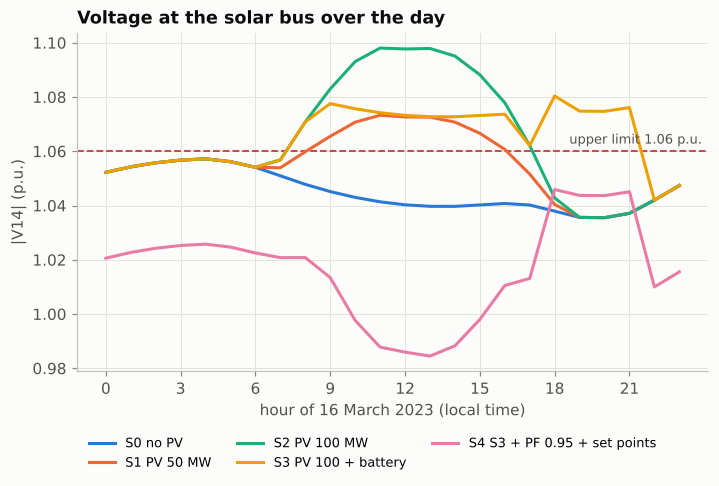

In [6]:
fig, ax = plt.subplots(figsize=(7.4, 4.0))
hours = CF.index.hour
for (k, m), c in zip(runs.items(), SERIES):
    ax.plot(hours, m.buses_t.v_mag_pu["14"].values, color=c, label=k)
limit_line(ax, V_MAX, "upper limit 1.06 p.u.", color=CRITICAL)
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("hour of 16 March 2023 (local time)")
ax.set_ylabel("|V14| (p.u.)"); ax.set_title("Voltage at the solar bus over the day")
ax.legend(loc="upper left", fontsize=8.5, ncol=3, bbox_to_anchor=(0, -0.16))
save(fig, FIG / "cs06_day_v14.png")
fig

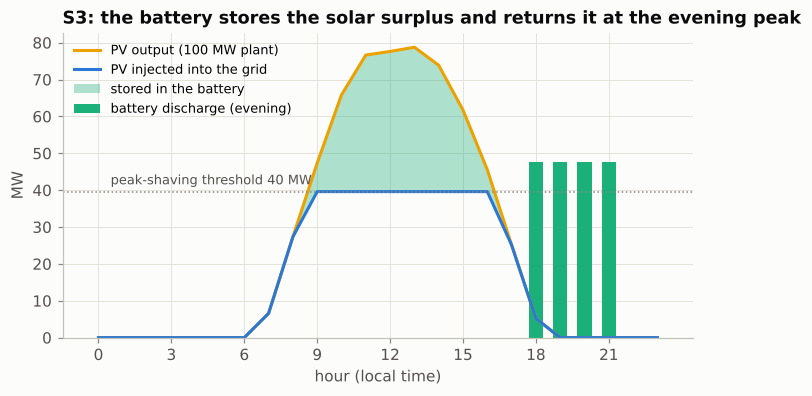

In [7]:
m3 = runs["S3 PV 100 + battery"]
fig, ax = plt.subplots(figsize=(7.4, 3.6))
pv = m3.generators_t.p_set["pv14"]
bat = m3.storage_units_t.p_set["battery14"]
ax.plot(hours, pv.values, color=ENTITY["solar"], label="PV output (100 MW plant)")
ax.plot(hours, (pv + bat.clip(upper=0)).values, color=SERIES[0], label="PV injected into the grid")
ax.fill_between(hours, (pv + bat.clip(upper=0)).values, pv.values, color=ENTITY["battery"], alpha=0.35,
                lw=0, label="stored in the battery")
ax.bar(hours, bat.clip(lower=0).values, color=ENTITY["battery"], width=0.6, label="battery discharge (evening)")
thr = shaving_threshold(pv)
ax.axhline(thr, color=MUTED, ls=":", lw=1)
ax.annotate(f"peak-shaving threshold {thr:.0f} MW", (0.5, thr + 2), fontsize=8.5, color=INK2)
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("hour (local time)"); ax.set_ylabel("MW")
ax.set_title("S3: the battery stores the solar surplus and returns it at the evening peak")
ax.legend(loc="upper left", fontsize=8.5)
save(fig, FIG / "cs06_battery_day.png")
fig

## 7. Interpretation
* **The voltage plan comes first.** With the original IEEE set points (up to 1.09 p.u.) the
  customer buses already exceed 1.06 p.u. at low load (15 hours a day in S0, without any
  PV), and the hosting capacity of bus 14 is only about 3 MW. Lowering the generator set
  points by 0.03 p.u. - a free operational decision - raises it to about 66 MW.
* **Reactive control doubles it again.** Inverters absorbing reactive power at PF 0.95 bring
  the hosting capacity to about 129 MW; beyond that the absorbed reactive power pulls some
  voltages below 0.94 p.u. (the limit changes from overvoltage to undervoltage).
* **The binding constraint is voltage, not current**: line loadings stay well below their
  ratings until about 150 MW.
* **Reverse power flow** appears as soon as the PV output exceeds the local load (about
  14 MW at noon): bus 14 becomes an exporter for most of the sunny hours (up to 62 MW in S2).
* **The battery (S3)** cuts the top of the solar curve: the peak voltage at bus 14 falls from
  1.098 to 1.080 p.u., the maximum export from 62 to 37 MW, and the daily losses decrease.
  But discharging 45 MW **at the weak bus** in the evening raises the voltage there too:
  a battery must be dispatched with voltage in mind, not only energy.
* **The full package (S4)**: battery + PF 0.95 + lower set points removes every overvoltage
  hour (highest customer voltage 1.046 p.u.).

**Recommendations:** (1) review the voltage plan before connecting solar; (2) require
reactive capability (PF 0.95 absorbing or volt-var) in the grid code; (3) size storage on
the energy above the hosting capacity and give it a voltage-aware dispatch; (4) keep
curtailment of the last MW as the low-cost safety valve; (5) re-check protections for
bidirectional flows.

In [8]:
pscs.save_summary("cs06", {
    "hosting_capacity": {k: list(v) for k, v in HC.items()},
    "load14_noon": load14_noon, "scenarios": summary.to_dict(orient="index"),
})